In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
from google.colab import files
uploaded = files.upload()

Saving BlinkIT Grocery Data.csv to BlinkIT Grocery Data (1).csv


In [9]:
df=pd.read_csv("BlinkIT Grocery Data.csv")

In [10]:
df.head()

,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
0,Regular,FDX32,Fruits and Vegetables,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.100014,15.10,145.4786,5.0
1,Low Fat,NCB42,Health and Hygiene,2022,OUT018,Tier 3,Medium,Supermarket Type2,0.008596,11.80,115.3492,5.0
2,Regular,FDR28,Frozen Foods,2016,OUT046,Tier 1,Small,Supermarket Type1,0.025896,13.85,165.0210,5.0
3,Regular,FDL50,Canned,2014,OUT013,Tier 3,High,Supermarket Type1,0.042278,12.15,126.5046,5.0
4,Low Fat,DRI25,Soft Drinks,2015,OUT045,Tier 2,Small,Supermarket Type1,0.033970,19.60,55.1614,5.0


In [11]:
df.describe()

,Outlet Establishment Year,Item Visibility,Item Weight,Sales,Rating
count,8523.000000,8523.000000,7060.000000,8523.000000,8523.000000
mean,2016.450546,0.066132,12.857645,140.992783,3.965857
std,3.189396,0.051598,4.643456,62.275067,0.605651
min,2011.000000,0.000000,4.555000,31.290000,1.000000
25%,2014.000000,0.026989,8.773750,93.826500,4.000000
50%,2016.000000,0.053931,12.600000,143.012800,4.000000
75%,2018.000000,0.094585,16.850000,185.643700,4.200000
max,2022.000000,0.328391,21.350000,266.888400,5.000000


In [16]:
df.isnull()

,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
0,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...
8518,False,False,False,False,False,False,False,False,False,True,False,False
8519,False,False,False,False,False,False,False,False,False,True,False,False
8520,False,False,False,False,False,False,False,False,False,True,False,False
8521,False,False,False,False,False,False,False,False,False,True,False,False


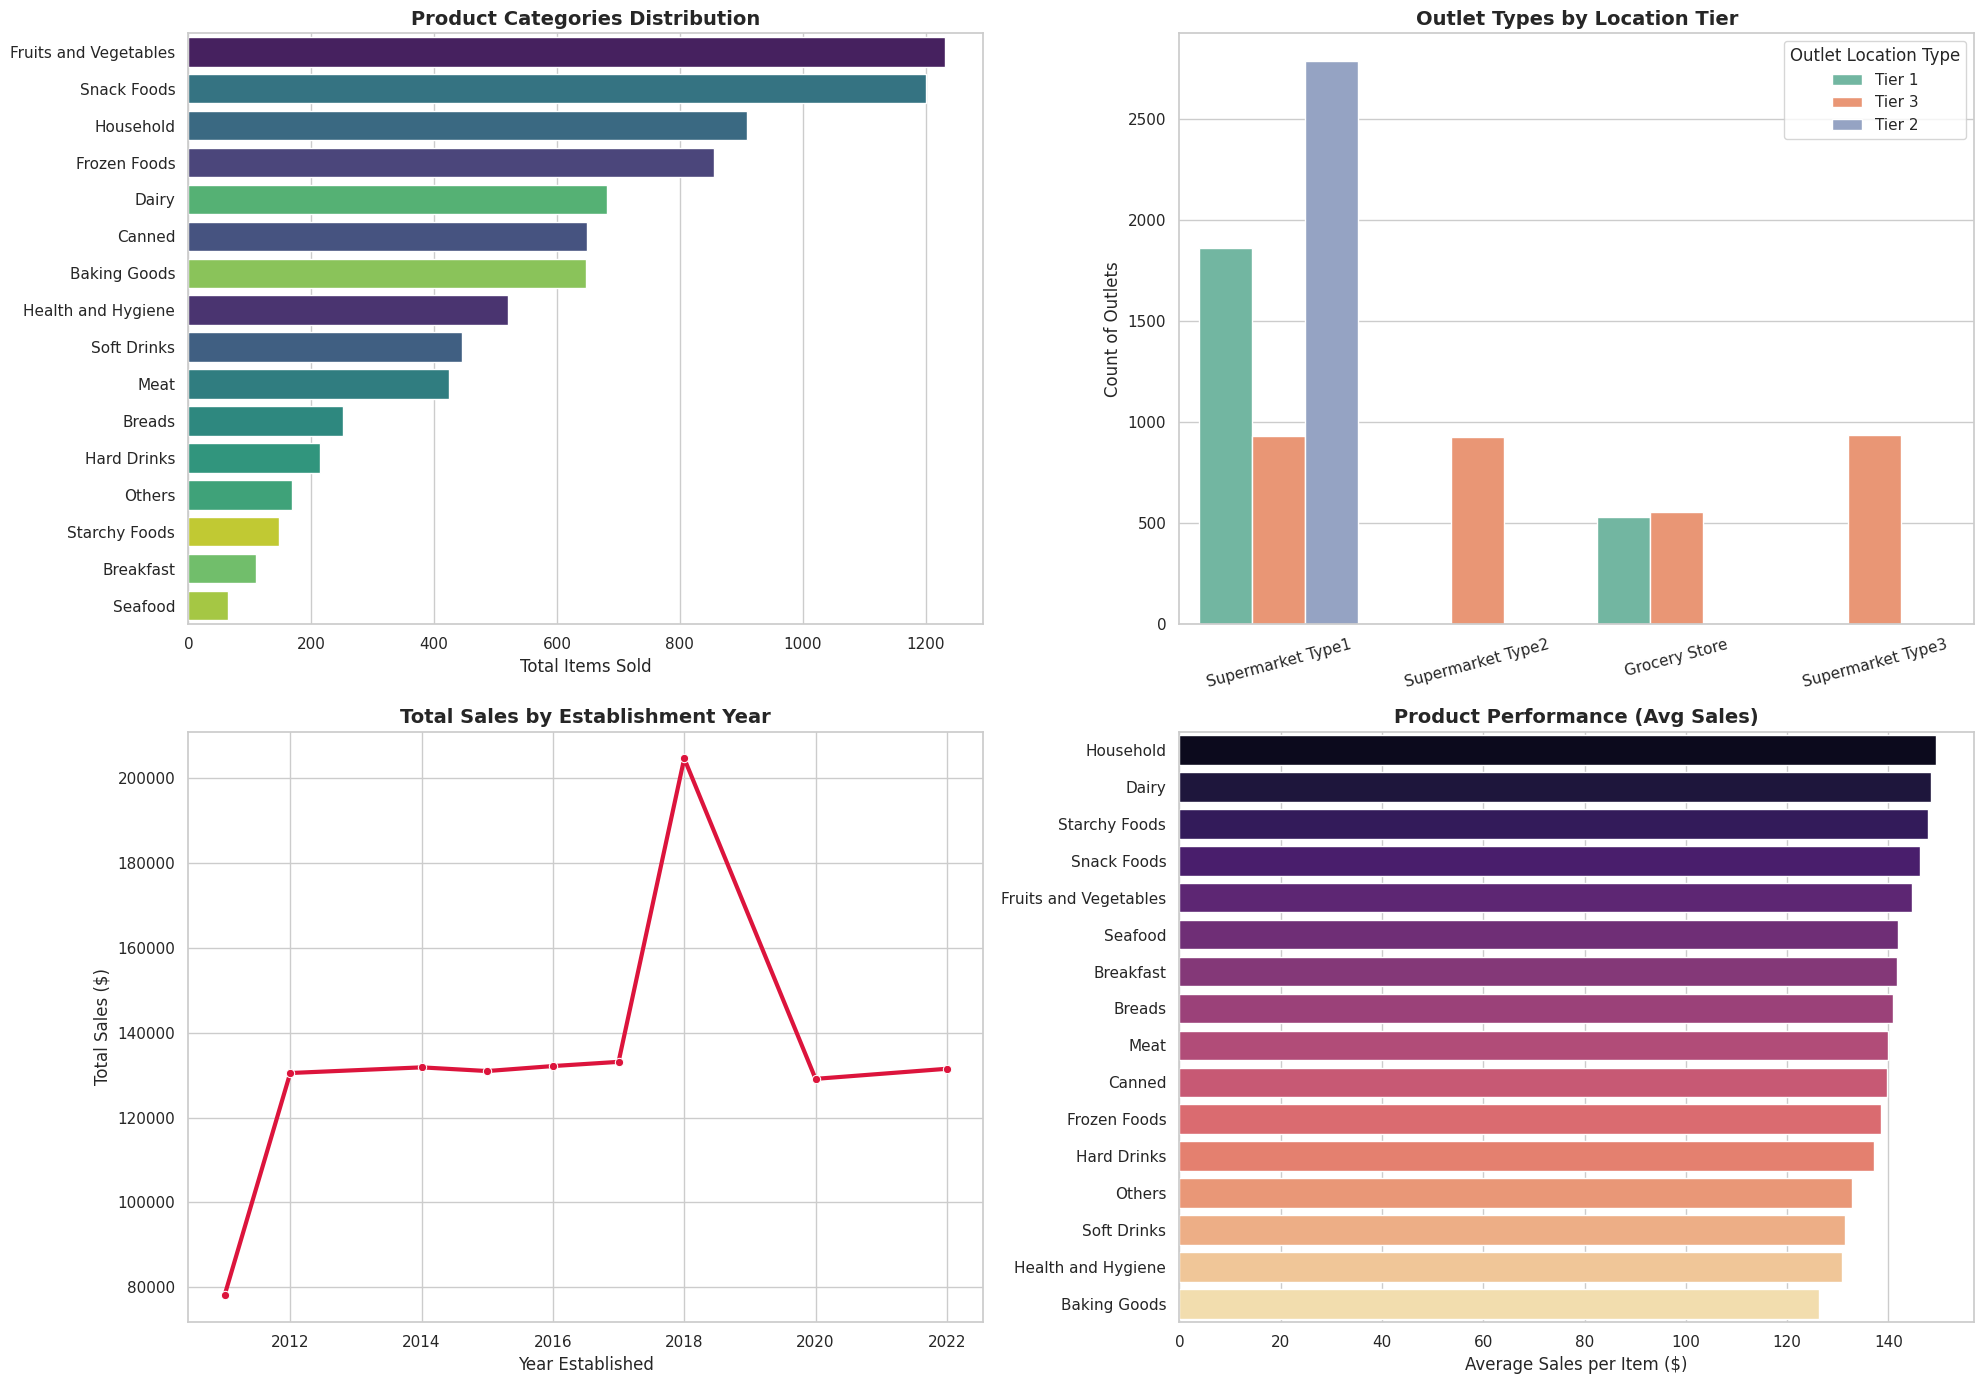

--- Overall BlinkIT Summary Metrics ---
Total Products Cataloged: 8523
Total Combined Sales:    $1,201,681.49
Average Customer Rating:  3.97 / 5.0


In [20]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(20, 14))

#Product Types & Variety
product_order = df['Item Type'].value_counts().index
sns.countplot(ax=axes[0, 0], data=df, y='Item Type', order=product_order, palette='viridis', hue='Item Type', legend=False)
axes[0, 0].set_title('Product Categories Distribution', fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel('Total Items Sold')
axes[0, 0].set_ylabel('')

#Outlet Types & Locations
sns.countplot(ax=axes[0, 1], data=df, x='Outlet Type', hue='Outlet Location Type', palette='Set2')
axes[0, 1].set_title('Outlet Types by Location Tier', fontsize=14, fontweight='bold')
axes[0, 1].tick_params(axis='x', rotation=15)
axes[0, 1].set_xlabel('')
axes[0, 1].set_ylabel('Count of Outlets')

#Overall Sales Trend over Establishment Years
sales_by_year = df.groupby('Outlet Establishment Year')['Sales'].sum().reset_index()
sns.lineplot(ax=axes[1, 0], data=sales_by_year, x='Outlet Establishment Year', y='Sales', marker='o', linewidth=3, color='crimson')
axes[1, 0].set_title('Total Sales by Establishment Year', fontsize=14, fontweight='bold')
axes[1, 0].set_xlabel('Year Established')
axes[1, 0].set_ylabel('Total Sales ($)')

#Product Performance (Average Sales by Category)
perf_by_cat = df.groupby('Item Type')['Sales'].mean().sort_values(ascending=False).reset_index()
sns.barplot(ax=axes[1, 1], data=perf_by_cat, x='Sales', y='Item Type', palette='magma', hue='Item Type', legend=False)
axes[1, 1].set_title('Product Performance (Avg Sales)', fontsize=14, fontweight='bold')
axes[1, 1].set_xlabel('Average Sales per Item ($)')
axes[1, 1].set_ylabel('')

plt.tight_layout()
plt.show()

# Print summary metrics
print(f"--- Overall BlinkIT Summary Metrics ---")
print(f"Total Products Cataloged: {len(df)}")
print(f"Total Combined Sales:    ${df['Sales'].sum():,.2f}")
print(f"Average Customer Rating:  {df['Rating'].mean():.2f} / 5.0")

In [21]:
#Check for Missing Values
print("Missing Values per Column")
missing_info = df.isnull().sum()
display(missing_info[missing_info > 0])

#Check for Duplicate Records
print("\nDuplicate Records")
duplicates_count = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicates_count}")

#Check for Outliers (Unusually high or low values)
print("\nRange & Outlier Detection (Descriptive Stats)")
display(df[['Sales', 'Rating', 'Item Weight', 'Item Visibility']].describe())

#Check for Inconsistent Categorical Representations
print("\nCategorical Column Consistency Check")
for col in ['Item Fat Content', 'Outlet Size', 'Outlet Location Type', 'Outlet Type']:
    print(f"\nUnique values in '{col}':")
    print(df[col].value_counts(dropna=False))

Missing Values per Column


,0
Item Weight,1463



Duplicate Records
Number of duplicate rows: 0

Range & Outlier Detection (Descriptive Stats)


,Sales,Rating,Item Weight,Item Visibility
count,8523.000000,8523.000000,7060.000000,8523.000000
mean,140.992783,3.965857,12.857645,0.066132
std,62.275067,0.605651,4.643456,0.051598
min,31.290000,1.000000,4.555000,0.000000
25%,93.826500,4.000000,8.773750,0.026989
50%,143.012800,4.000000,12.600000,0.053931
75%,185.643700,4.200000,16.850000,0.094585
max,266.888400,5.000000,21.350000,0.328391



Categorical Column Consistency Check

Unique values in 'Item Fat Content':
Item Fat Content
Low Fat    5089
Regular    2889
LF          316
reg         117
low fat     112
Name: count, dtype: int64

Unique values in 'Outlet Size':
Outlet Size
Medium    3631
Small     3139
High      1753
Name: count, dtype: int64

Unique values in 'Outlet Location Type':
Outlet Location Type
Tier 3    3350
Tier 2    2785
Tier 1    2388
Name: count, dtype: int64

Unique values in 'Outlet Type':
Outlet Type
Supermarket Type1    5577
Grocery Store        1083
Supermarket Type3     935
Supermarket Type2     928
Name: count, dtype: int64


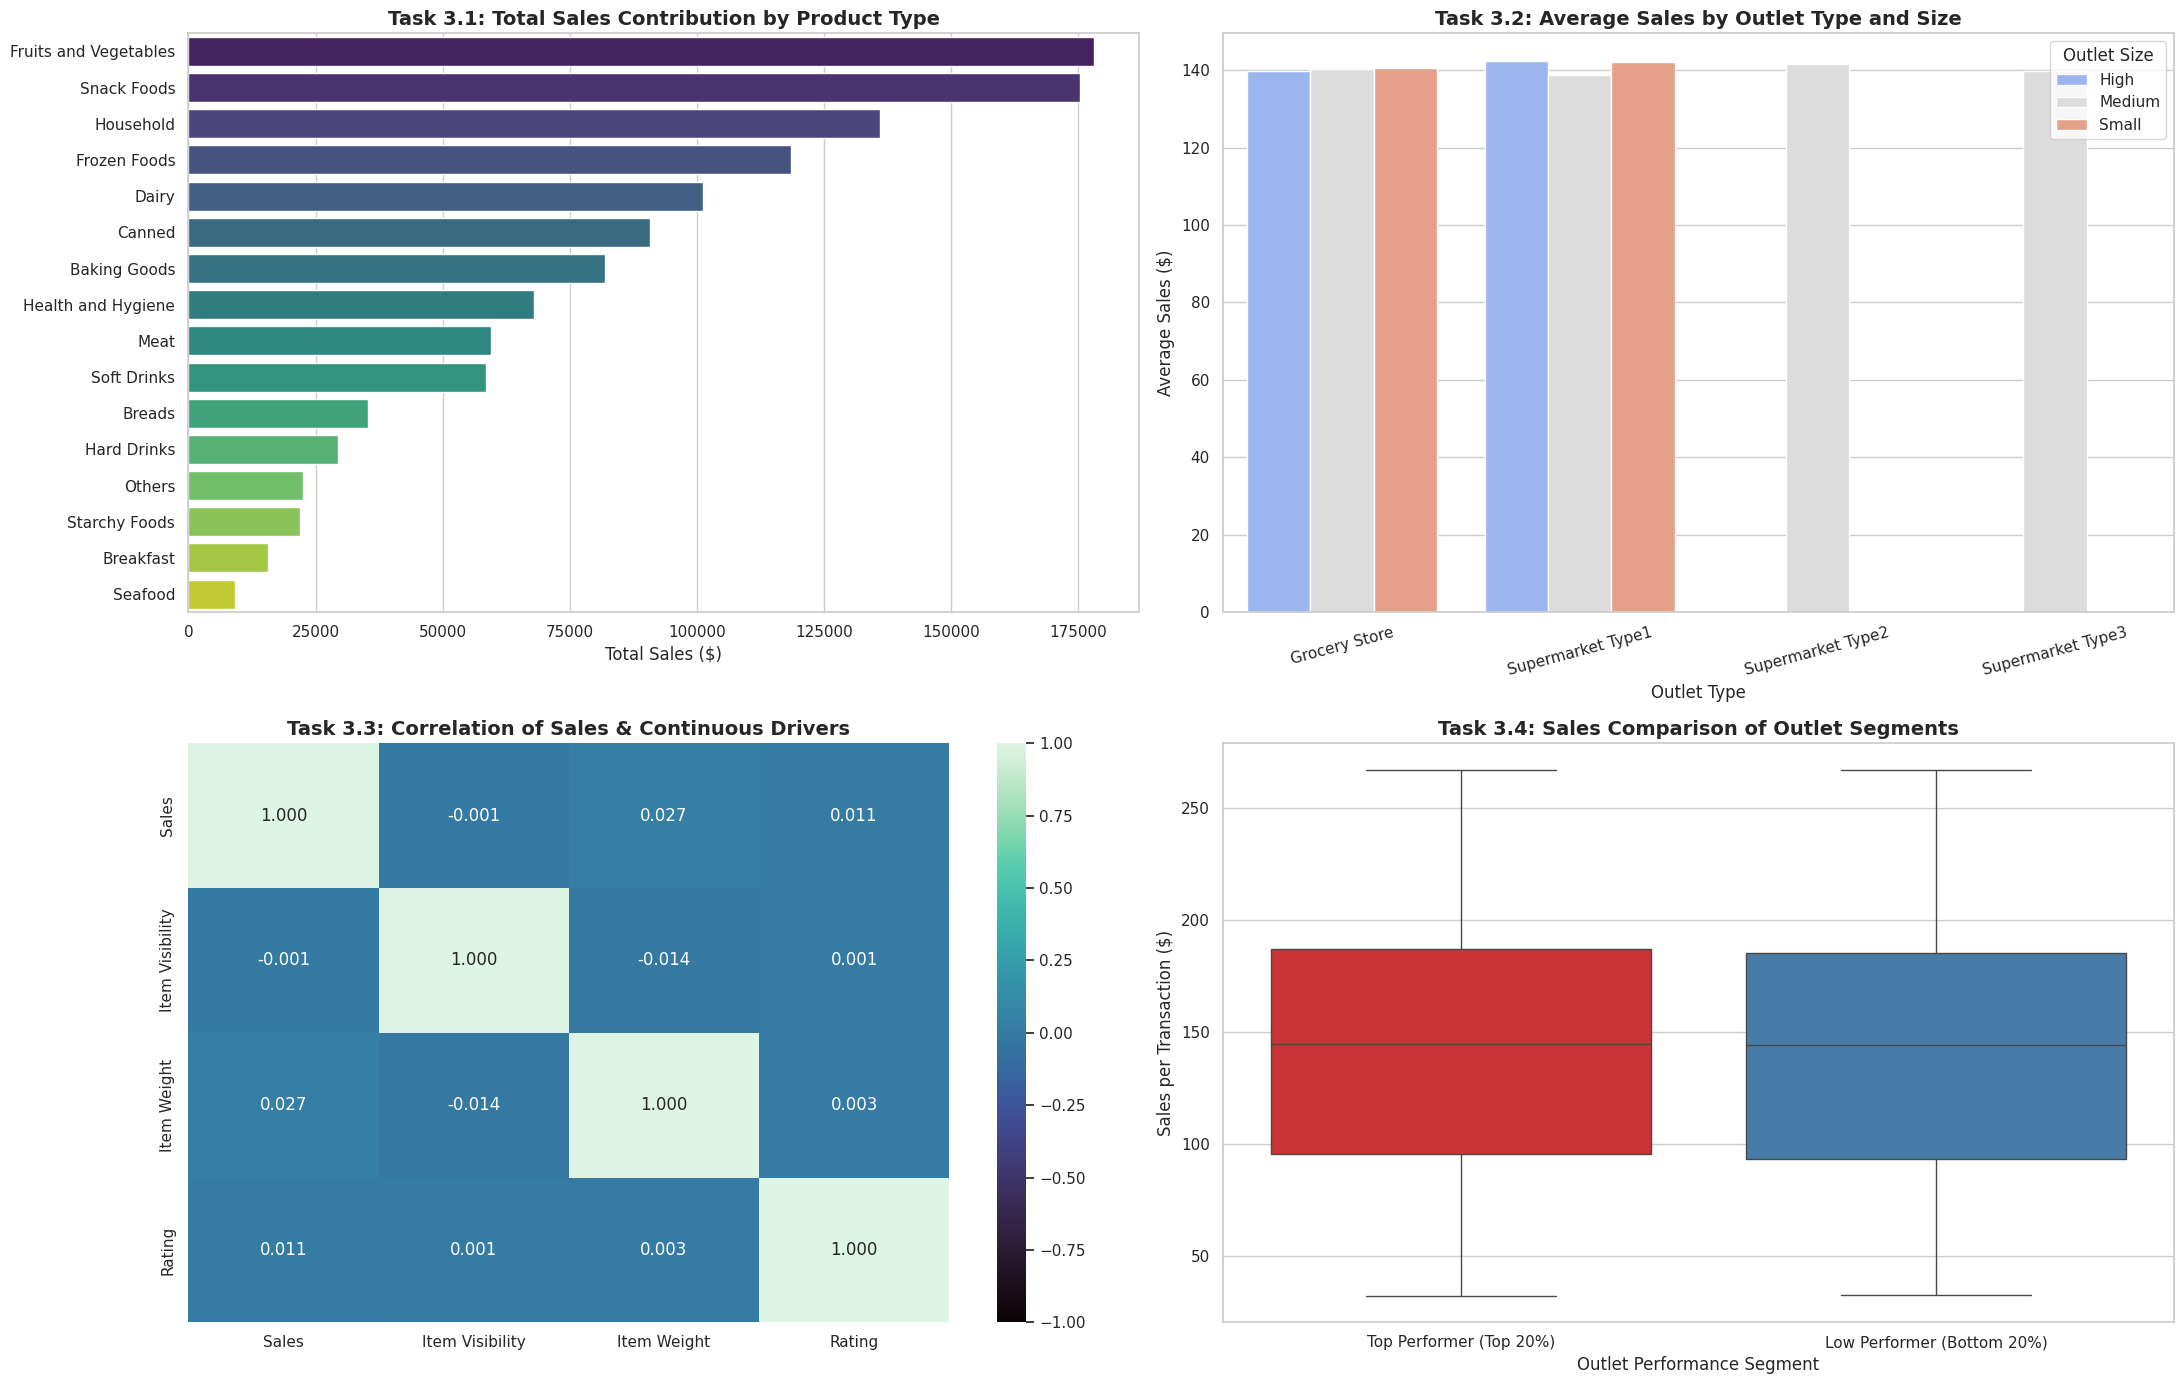


Drivers of Sales Analysis Summary

Top 3 Product Types by Total Sales:
            Item Type       Sales
Fruits and Vegetables 178124.0810
          Snack Foods 175433.9224
            Household 135976.5254

Correlation of Sales with other factors:
Sales              1.000000
Item Weight        0.027141
Rating             0.011329
Item Visibility   -0.001315
Name: Sales, dtype: float64


In [22]:
# Configure plot style
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(22, 14))

#Sales by Product Types
product_sales = df.groupby('Item Type')['Sales'].sum().sort_values(ascending=False).reset_index()
sns.barplot(ax=axes[0, 0], data=product_sales, x='Sales', y='Item Type', palette='viridis', hue='Item Type', legend=False)
axes[0, 0].set_title('Task 3.1: Total Sales Contribution by Product Type', fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel('Total Sales ($)')
axes[0, 0].set_ylabel('')

#Sales by Outlet Type and Size
outlet_sales = df.groupby(['Outlet Type', 'Outlet Size'])['Sales'].mean().reset_index()
sns.barplot(ax=axes[0, 1], data=outlet_sales, x='Outlet Type', y='Sales', hue='Outlet Size', palette='coolwarm')
axes[0, 1].set_title('Task 3.2: Average Sales by Outlet Type and Size', fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel('Outlet Type')
axes[0, 1].set_ylabel('Average Sales ($)')
axes[0, 1].tick_params(axis='x', rotation=15)

# Connection of Sales with Visibility, Weight, and Ratings
# Compute correlation matrix for numeric indicators
corr_cols = ['Sales', 'Item Visibility', 'Item Weight', 'Rating']
corr_matrix = df[corr_cols].corr()
sns.heatmap(ax=axes[1, 0], data=corr_matrix, annot=True, cmap='mako', vmin=-1, vmax=1, fmt='.3f')
axes[1, 0].set_title('Task 3.3: Correlation of Sales & Continuous Drivers', fontsize=14, fontweight='bold')

#Compare Top 20% vs Bottom 20% Outlets
outlet_totals = df.groupby('Outlet Identifier')['Sales'].sum().sort_values(ascending=False).reset_index()
q_high = outlet_totals['Sales'].quantile(0.8)
q_low = outlet_totals['Sales'].quantile(0.2)

top_outlets = outlet_totals[outlet_totals['Sales'] >= q_high]['Outlet Identifier'].tolist()
bottom_outlets = outlet_totals[outlet_totals['Sales'] <= q_low]['Outlet Identifier'].tolist()

df['Performance Segment'] = 'Average'
df.loc[df['Outlet Identifier'].isin(top_outlets), 'Performance Segment'] = 'Top Performer (Top 20%)'
df.loc[df['Outlet Identifier'].isin(bottom_outlets), 'Performance Segment'] = 'Low Performer (Bottom 20%)'

sns.boxplot(ax=axes[1, 1], data=df[df['Performance Segment'] != 'Average'], x='Performance Segment', y='Sales', hue='Performance Segment', palette='Set1', legend=False)
axes[1, 1].set_title('Task 3.4: Sales Comparison of Outlet Segments', fontsize=14, fontweight='bold')
axes[1, 1].set_xlabel('Outlet Performance Segment')
axes[1, 1].set_ylabel('Sales per Transaction ($)')

plt.tight_layout()
plt.show()

# Print summary details
print("\nDrivers of Sales Analysis Summary")
print(f"\nTop 3 Product Types by Total Sales:")
print(product_sales.head(3).to_string(index=False))

print(f"\nCorrelation of Sales with other factors:")
print(corr_matrix['Sales'].sort_values(ascending=False))

In [23]:
top_products = df.groupby('Item Type')['Sales'].sum().sort_values(ascending=False).head(5).reset_index()

#Top performing outlet locations and types
top_locations = df.groupby('Outlet Location Type')['Sales'].sum().sort_values(ascending=False).reset_index()
top_outlet_types = df.groupby('Outlet Type')['Sales'].sum().sort_values(ascending=False).reset_index()

bottom_products = df.groupby('Item Type')['Sales'].sum().sort_values(ascending=True).head(3).reset_index()

# Bottom 2 performing Outlets
bottom_outlets_sales = df.groupby('Outlet Identifier')['Sales'].sum().sort_values(ascending=True).head(2).reset_index()

# Displaying the findings to support Task
print("MANAGEMENT DECISION SUPPORT DASHBOARD")
print("\nTop 5 Product Categories (Focus Inventory & Promotion)")
display(top_products)

print("\nTop Locations & Outlet Types (Expansion targets)")
print("\nSales by Location Tier:")
display(top_locations)
print("\nSales by Outlet Type:")
display(top_outlet_types)

print("\nAreas of Improvement (Low sales or efficiency)")
print("\nLowest Sales Categories:")
display(bottom_products)
print("\nLowest Performing Outlets:")
display(bottom_outlets_sales)

MANAGEMENT DECISION SUPPORT DASHBOARD

Top 5 Product Categories (Focus Inventory & Promotion)


,Item Type,Sales
0,Fruits and Vegetables,178124.0810
1,Snack Foods,175433.9224
2,Household,135976.5254
3,Frozen Foods,118558.8814
4,Dairy,101276.4616



Top Locations & Outlet Types (Expansion targets)

Sales by Location Tier:


,Outlet Location Type,Sales
0,Tier 3,472133.0332
1,Tier 2,393150.6476
2,Tier 1,336397.8120



Sales by Outlet Type:


,Outlet Type,Sales
0,Supermarket Type1,787549.8928
1,Grocery Store,151939.1490
2,Supermarket Type2,131477.7764
3,Supermarket Type3,130714.6746



Areas of Improvement (Low sales or efficiency)

Lowest Sales Categories:


,Item Type,Sales
0,Seafood,9077.8700
1,Breakfast,15596.6966
2,Starchy Foods,21880.0274



Lowest Performing Outlets:


,Outlet Identifier,Sales
0,OUT019,73807.5824
1,OUT010,78131.5666
